# Aula pratica de analise estatística

Este notebook apresenta um fluxo completo de preparação e análise estatística exploratória antes da modelagem preditiva. São abordadas auditoria da base, limpeza, valores ausentes, duplicatas, validação de domínio, estatística descritiva, intervalos de confiança, distribuições, normalidade, outliers, comparações entre grupos, associações entre variáveis categóricas, correlações e análise de componentes principais. Não são aplicados modelos de regressão ou classificação.

A base pública Palmer Penguins reúne medições de 344 pinguins de três espécies observadas em três ilhas do arquipélago Palmer, na Antártida. Os dados foram disponibilizados por Kristen Gorman e pela Palmer Station Antarctica LTER. Fonte: [palmerpenguins](https://allisonhorst.github.io/palmerpenguins/). Licença: CC0. Citação principal: Horst, Hill e Gorman (2020), DOI [10.5281/zenodo.3960218](https://doi.org/10.5281/zenodo.3960218).

## 1. Preparação do ambiente

As bibliotecas utilizadas já estão disponíveis no Google Colab. A semente aleatória fixa permite reproduzir os resultados de procedimentos de reamostragem.

In [ ]:
import itertools
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy
import sklearn
try:
    from IPython.display import display
except ImportError:
    display = print
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

versoes = pd.Series({
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'seaborn': sns.__version__,
    'scipy': scipy.__version__,
    'scikit-learn': sklearn.__version__,
}, name='versão')
display(versoes.to_frame())

def ajuste_holm(p_valores):
    p = np.asarray(p_valores, dtype=float)
    m = p.size
    ordem = np.argsort(p)
    p_ordenados = p[ordem]
    fatores = m - np.arange(m)
    ajustados_ordenados = np.maximum.accumulate(p_ordenados * fatores)
    ajustados_ordenados = np.clip(ajustados_ordenados, 0, 1)
    ajustados = np.empty_like(ajustados_ordenados)
    ajustados[ordem] = ajustados_ordenados
    return ajustados

def anova_welch(grupos):
    grupos = [np.asarray(g, dtype=float) for g in grupos]
    tamanhos = np.array([len(g) for g in grupos], dtype=float)
    medias = np.array([g.mean() for g in grupos])
    variancias = np.array([g.var(ddof=1) for g in grupos])
    pesos = tamanhos / variancias
    soma_pesos = pesos.sum()
    media_ponderada = np.sum(pesos * medias) / soma_pesos
    k = len(grupos)
    numerador = np.sum(pesos * (medias - media_ponderada) ** 2) / (k - 1)
    termo = np.sum(((1 - pesos / soma_pesos) ** 2) / (tamanhos - 1))
    correcao = 1 + (2 * (k - 2) / (k ** 2 - 1)) * termo
    estatistica_f = numerador / correcao
    gl_1 = k - 1
    gl_2 = (k ** 2 - 1) / (3 * termo)
    p_valor = stats.f.sf(estatistica_f, gl_1, gl_2)
    return estatistica_f, p_valor, gl_1, gl_2

,versão
pandas,2.2.3
numpy,2.1.3
seaborn,0.13.2
scipy,1.16.3
scikit-learn,1.6.1


## 2. Carregamento da base pública

A leitura é feita diretamente do arquivo CSV mantido no repositório oficial do projeto. A cópia original é preservada em `df_raw`; todas as transformações posteriores são aplicadas a uma cópia.

In [ ]:
DATA_URL = (
    'https://raw.githubusercontent.com/allisonhorst/'
    'palmerpenguins/main/inst/extdata/penguins.csv'
)

df_raw = pd.read_csv(DATA_URL)

colunas_esperadas = {
    'species', 'island', 'bill_length_mm', 'bill_depth_mm',
    'flipper_length_mm', 'body_mass_g', 'sex', 'year'
}
assert set(df_raw.columns) == colunas_esperadas, (
    'O esquema da fonte foi alterado. Revise as colunas antes de continuar.'
)

print(f'Dimensões originais: {df_raw.shape[0]} linhas e {df_raw.shape[1]} colunas')
display(df_raw.head())

Dimensões originais: 344 linhas e 8 colunas


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1000,18.7000,181.0000,"3,750.0000",male,2007
1,Adelie,Torgersen,39.5000,17.4000,186.0000,"3,800.0000",female,2007
2,Adelie,Torgersen,40.3000,18.0000,195.0000,"3,250.0000",female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7000,19.3000,193.0000,"3,450.0000",female,2007


### Dicionário de dados

| Variável | Tipo conceitual | Descrição |
|:---|:---|:---|
| `species` | Categórica nominal | Espécie do pinguim |
| `island` | Categórica nominal | Ilha onde o animal foi observado |
| `bill_length_mm` | Numérica contínua | Comprimento do bico, em milímetros |
| `bill_depth_mm` | Numérica contínua | Profundidade do bico, em milímetros |
| `flipper_length_mm` | Numérica contínua | Comprimento da nadadeira, em milímetros |
| `body_mass_g` | Numérica contínua | Massa corporal, em gramas |
| `sex` | Categórica nominal | Sexo registrado |
| `year` | Categórica temporal | Ano da observação |

## 3. Auditoria e limpeza dos dados

A auditoria inicial verifica estrutura, tipos computacionais, quantidade de valores distintos, ausências e duplicatas. Essa etapa deve ocorrer antes de qualquer cálculo estatístico.

In [ ]:
df_raw.info()

def resumo_qualidade(dados):
    resumo = pd.DataFrame({
        'tipo': dados.dtypes.astype(str),
        'não_nulos': dados.notna().sum(),
        'ausentes': dados.isna().sum(),
        'ausentes_%': dados.isna().mean().mul(100),
        'valores_distintos': dados.nunique(dropna=True),
    })
    return resumo.sort_values('ausentes_%', ascending=False)

display(resumo_qualidade(df_raw))
print(f'Linhas completamente duplicadas: {df_raw.duplicated().sum()}')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


,tipo,não_nulos,ausentes,ausentes_%,valores_distintos
sex,object,333,11,3.1977,2
bill_depth_mm,float64,342,2,0.5814,80
flipper_length_mm,float64,342,2,0.5814,55
bill_length_mm,float64,342,2,0.5814,164
body_mass_g,float64,342,2,0.5814,94
island,object,344,0,0.0000,3
species,object,344,0,0.0000,3
year,int64,344,0,0.0000,3


Linhas completamente duplicadas: 0


### Estratégia de limpeza

Os nomes das colunas são padronizados, espaços residuais são removidos, categorias recebem capitalização consistente e as colunas quantitativas são convertidas explicitamente para números. Regras de domínio identificam valores fisicamente incompatíveis com as unidades da base. Linhas completamente duplicadas são removidas. Ausências não são preenchidas na base limpa, pois a imputação altera distribuições e incertezas. Cada análise utiliza os casos disponíveis. A única exceção ocorre na PCA, que exige matriz completa e utiliza imputação pela mediana documentada no próprio fluxo.

In [ ]:
df = df_raw.copy(deep=True)

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r'[^a-z0-9]+', '_', regex=True)
    .str.strip('_')
)

colunas_categoricas = ['species', 'island', 'sex']
colunas_numericas = [
    'bill_length_mm', 'bill_depth_mm',
    'flipper_length_mm', 'body_mass_g'
]

for coluna in colunas_categoricas:
    df[coluna] = df[coluna].astype('string').str.strip().str.title()

for coluna in colunas_numericas:
    df[coluna] = pd.to_numeric(df[coluna], errors='coerce')

df['year'] = pd.to_numeric(df['year'], errors='coerce').astype('Int64')

regras_dominio = {
    'bill_length_mm': df['bill_length_mm'].between(20, 70),
    'bill_depth_mm': df['bill_depth_mm'].between(10, 30),
    'flipper_length_mm': df['flipper_length_mm'].between(150, 250),
    'body_mass_g': df['body_mass_g'].between(2000, 7000),
    'year': df['year'].between(2007, 2009),
}

invalidos = {}
for coluna, mascara_valida in regras_dominio.items():
    mascara_invalida = df[coluna].notna() & ~mascara_valida
    invalidos[coluna] = int(mascara_invalida.sum())
    df.loc[mascara_invalida, coluna] = pd.NA if coluna == 'year' else np.nan

duplicatas_removidas = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

for coluna in colunas_categoricas + ['year']:
    df[coluna] = df[coluna].astype('category')

print('Valores incompatíveis com as regras de domínio:', invalidos)
print('Duplicatas removidas:', duplicatas_removidas)
print('Dimensões após a limpeza:', df.shape)
display(resumo_qualidade(df))

Valores incompatíveis com as regras de domínio: {'bill_length_mm': 0, 'bill_depth_mm': 0, 'flipper_length_mm': 0, 'body_mass_g': 0, 'year': 0}
Duplicatas removidas: 0
Dimensões após a limpeza: (344, 8)


,tipo,não_nulos,ausentes,ausentes_%,valores_distintos
sex,category,333,11,3.1977,2
bill_depth_mm,float64,342,2,0.5814,80
flipper_length_mm,float64,342,2,0.5814,55
bill_length_mm,float64,342,2,0.5814,164
body_mass_g,float64,342,2,0.5814,94
island,category,344,0,0.0000,3
species,category,344,0,0.0000,3
year,category,344,0,0.0000,3


### Padrões de ausência

O total por coluna quantifica a extensão do problema. O mapa mostra se as ausências aparecem concentradas nas mesmas linhas, informação relevante para decidir entre análise por casos disponíveis, exclusão completa ou imputação.

,n,percentual
sex,11,3.1977
bill_depth_mm,2,0.5814
flipper_length_mm,2,0.5814
bill_length_mm,2,0.5814
body_mass_g,2,0.5814
island,0,0.0000
species,0,0.0000
year,0,0.0000


,n_linhas
padrão_binário,
00000000,333
00000010,9
00111110,2


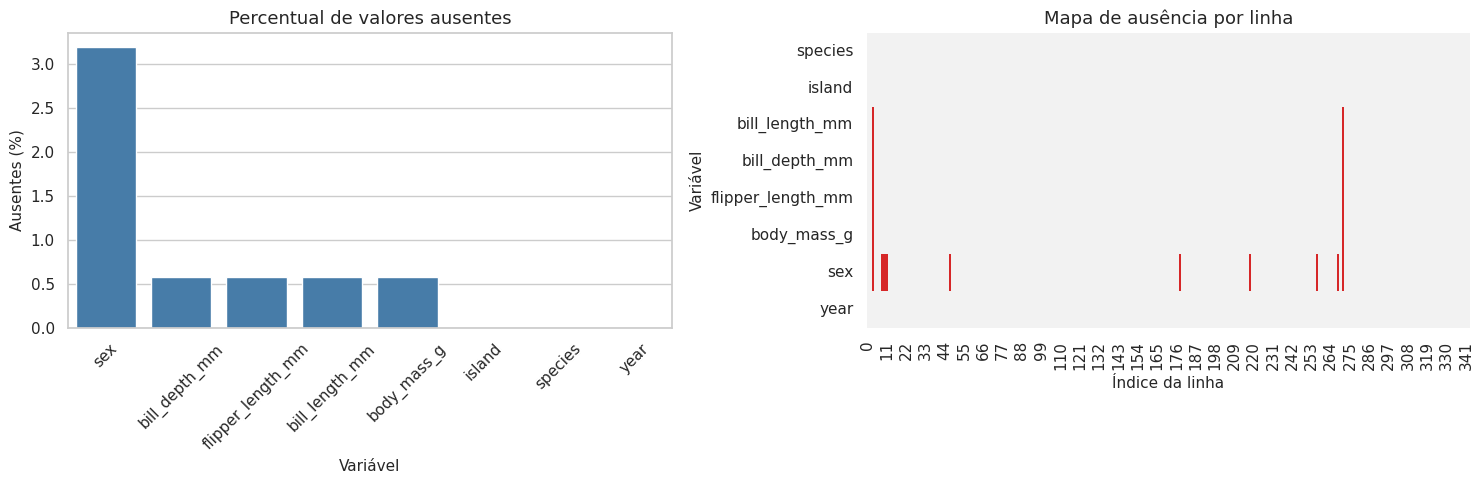

In [ ]:
ausencias = (
    df.isna().sum()
    .to_frame('n')
    .assign(percentual=lambda x: 100 * x['n'] / len(df))
    .sort_values('n', ascending=False)
)
display(ausencias)

padroes_ausencia = (
    df.isna().astype(int).astype(str).agg(''.join, axis=1)
    .value_counts()
    .rename_axis('padrão_binário')
    .to_frame('n_linhas')
)
display(padroes_ausencia.head(10))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=ausencias.index, y=ausencias['percentual'], ax=axes[0], color='#377eb8')
axes[0].set_title('Percentual de valores ausentes')
axes[0].set_xlabel('Variável')
axes[0].set_ylabel('Ausentes (%)')
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(df.isna().T, cmap=['#f2f2f2', '#d62728'], cbar=False, ax=axes[1])
axes[1].set_title('Mapa de ausência por linha')
axes[1].set_xlabel('Índice da linha')
axes[1].set_ylabel('Variável')
plt.tight_layout()
plt.show()

## 4. Estatística descritiva univariada

Medidas de posição, dispersão e forma resumem cada variável quantitativa. O coeficiente de variação facilita a comparação da dispersão relativa, enquanto assimetria e curtose descrevem a forma da distribuição.

In [ ]:
def resumo_numerico(dados, colunas):
    linhas = []
    for coluna in colunas:
        x = dados[coluna].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        media = x.mean()
        desvio = x.std(ddof=1)
        linhas.append({
            'variável': coluna,
            'n': x.size,
            'ausentes': dados[coluna].isna().sum(),
            'média': media,
            'mediana': x.median(),
            'desvio_padrão': desvio,
            'variância': x.var(ddof=1),
            'mínimo': x.min(),
            'q1': q1,
            'q3': q3,
            'máximo': x.max(),
            'iqr': q3 - q1,
            'cv_%': 100 * desvio / media if media != 0 else np.nan,
            'assimetria': stats.skew(x, bias=False),
            'curtose_excesso': stats.kurtosis(x, fisher=True, bias=False),
        })
    return pd.DataFrame(linhas).set_index('variável')

resumo_num = resumo_numerico(df, colunas_numericas)
display(resumo_num)

,n,ausentes,média,mediana,desvio_padrão,variância,mínimo,q1,q3,máximo,iqr,cv_%,assimetria,curtose_excesso
variável,,,,,,,,,,,,,,
bill_length_mm,342,2,43.9219,44.4500,5.4596,29.8071,32.1000,39.2250,48.5000,59.6000,9.2750,12.4302,0.0531,-0.8760
bill_depth_mm,342,2,17.1512,17.3000,1.9748,3.8998,13.1000,15.6000,18.7000,21.5000,3.1000,11.5140,-0.1435,-0.9069
flipper_length_mm,342,2,200.9152,197.0000,14.0617,197.7318,172.0000,190.0000,213.0000,231.0000,23.0000,6.9988,0.3457,-0.9843
body_mass_g,342,2,"4,201.7544","4,050.0000",801.9545,"643,131.0773","2,700.0000","3,550.0000","4,750.0000","6,300.0000","1,200.0000",19.0862,0.4703,-0.7192


As variáveis categóricas são resumidas por frequências absolutas e relativas. O parâmetro `dropna=False` mantém as ausências visíveis.

In [ ]:
for coluna in colunas_categoricas + ['year']:
    frequencias = df[coluna].value_counts(dropna=False)
    tabela = pd.DataFrame({
        'frequência': frequencias,
        'percentual': 100 * frequencias / len(df),
    })
    print(f'Variável: {coluna}')
    display(tabela)

Variável: species


,frequência,percentual
species,,
Adelie,152,44.1860
Gentoo,124,36.0465
Chinstrap,68,19.7674


Variável: island


,frequência,percentual
island,,
Biscoe,168,48.8372
Dream,124,36.0465
Torgersen,52,15.1163


Variável: sex


,frequência,percentual
sex,,
Male,168,48.8372
Female,165,47.9651
<NA>,11,3.1977


Variável: year


,frequência,percentual
year,,
2009,120,34.8837
2008,114,33.1395
2007,110,31.9767


### Distribuições e boxplots

Histogramas com estimativa de densidade revelam concentração, assimetria e possíveis misturas de grupos. Boxplots separados por espécie ajudam a distinguir valores extremos internos a cada espécie de diferenças naturais entre espécies.

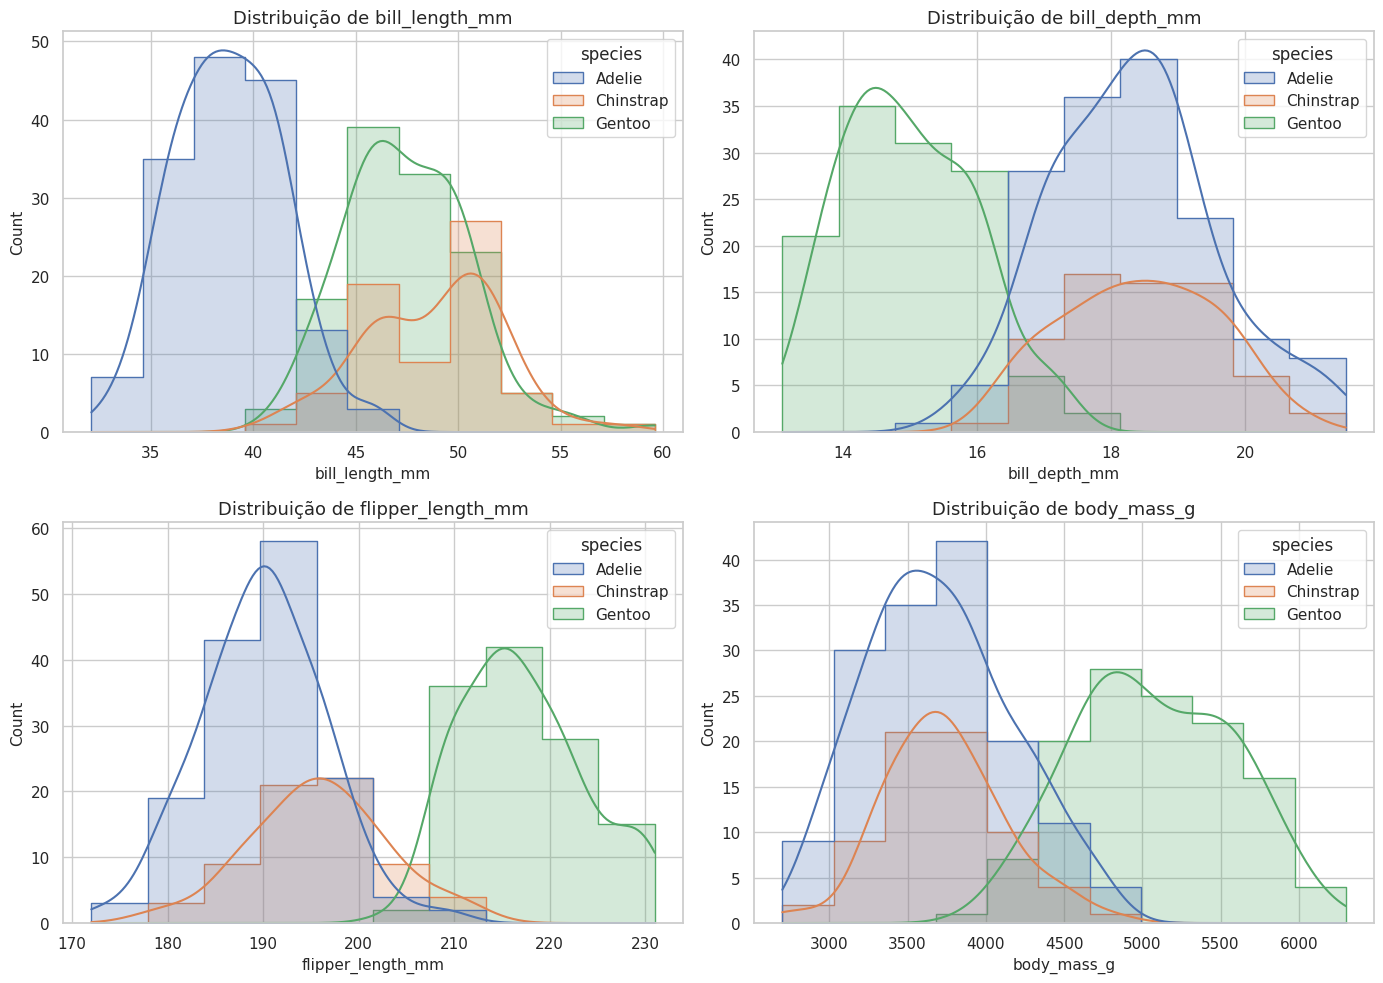

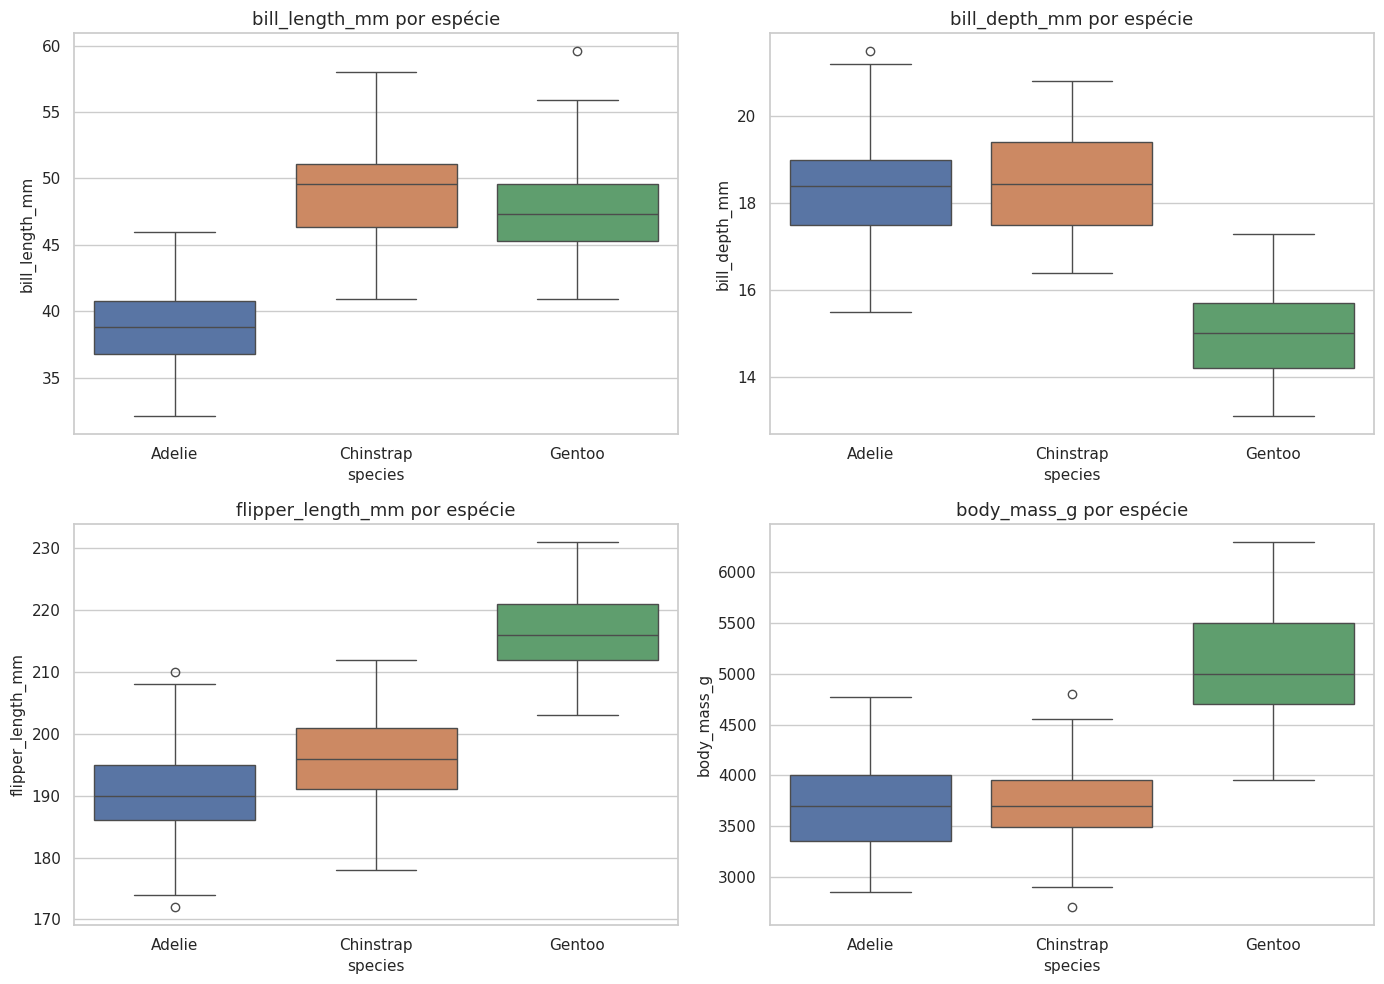

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for coluna, ax in zip(colunas_numericas, axes.flat):
    sns.histplot(data=df, x=coluna, hue='species', kde=True, element='step', ax=ax)
    ax.set_title(f'Distribuição de {coluna}')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for coluna, ax in zip(colunas_numericas, axes.flat):
    sns.boxplot(data=df, x='species', y=coluna, hue='species', legend=False, ax=ax)
    ax.set_title(f'{coluna} por espécie')
plt.tight_layout()
plt.show()

### Intervalos de confiança

O intervalo t de 95% estima a incerteza da média sob independência das observações. O exemplo de bootstrap estima o intervalo da mediana sem exigir normalidade, por meio de reamostragem com reposição.

In [ ]:
def intervalo_media_t(x, confianca=0.95):
    x = pd.Series(x).dropna().to_numpy()
    n = x.size
    media = x.mean()
    erro = stats.sem(x)
    critico = stats.t.ppf((1 + confianca) / 2, df=n - 1)
    return media, media - critico * erro, media + critico * erro, n

linhas_ic = []
for especie, grupo in df.groupby('species', observed=True):
    for coluna in colunas_numericas:
        media, inferior, superior, n = intervalo_media_t(grupo[coluna])
        linhas_ic.append({
            'espécie': especie, 'variável': coluna, 'n': n,
            'média': media, 'ic95_inferior': inferior, 'ic95_superior': superior
        })

ic_medias = pd.DataFrame(linhas_ic)
display(ic_medias)

def intervalo_bootstrap_mediana(x, n_reamostragens=5000, confianca=0.95):
    x = pd.Series(x).dropna().to_numpy()
    amostras = rng.choice(x, size=(n_reamostragens, x.size), replace=True)
    medianas = np.median(amostras, axis=1)
    alpha = 1 - confianca
    inferior, superior = np.quantile(medianas, [alpha / 2, 1 - alpha / 2])
    return np.median(x), inferior, superior

bootstrap_massa = []
for especie, grupo in df.groupby('species', observed=True):
    mediana, inferior, superior = intervalo_bootstrap_mediana(grupo['body_mass_g'])
    bootstrap_massa.append({
        'espécie': especie, 'mediana_massa_g': mediana,
        'ic95_bootstrap_inferior': inferior,
        'ic95_bootstrap_superior': superior,
    })
display(pd.DataFrame(bootstrap_massa))

,espécie,variável,n,média,ic95_inferior,ic95_superior
0,Adelie,bill_length_mm,151,38.7914,38.3631,39.2197
1,Adelie,bill_depth_mm,151,18.3464,18.1507,18.5420
2,Adelie,flipper_length_mm,151,189.9536,188.9021,191.0052
3,Adelie,body_mass_g,151,"3,700.6623","3,626.9262","3,774.3983"
4,Chinstrap,bill_length_mm,68,48.8338,48.0256,49.6421
5,Chinstrap,bill_depth_mm,68,18.4206,18.1458,18.6954
6,Chinstrap,flipper_length_mm,68,195.8235,194.0972,197.5498
7,Chinstrap,body_mass_g,68,"3,733.0882","3,640.0593","3,826.1171"
8,Gentoo,bill_length_mm,123,47.5049,46.9548,48.0550
9,Gentoo,bill_depth_mm,123,14.9821,14.8070,15.1573


,espécie,mediana_massa_g,ic95_bootstrap_inferior,ic95_bootstrap_superior
0,Adelie,"3,700.0000","3,550.0000","3,775.0000"
1,Chinstrap,"3,700.0000","3,625.0000","3,800.0000"
2,Gentoo,"5,000.0000","4,900.0000","5,200.0000"


### Avaliação de normalidade

O teste de Shapiro-Wilk é aplicado dentro de cada espécie, evitando interpretar como não normal uma distribuição global que apenas mistura grupos distintos. Como são executados vários testes, os valores p são corrigidos pelo método de Holm. Gráficos quantil-quantil complementam a decisão, pois testes de normalidade podem ser sensíveis ao tamanho amostral.

,espécie,variável,n,W,p_bruto,p_holm,rejeita_normalidade_5%
0,Adelie,bill_length_mm,151,0.9934,0.7166,1.0000,False
1,Adelie,bill_depth_mm,151,0.9847,0.0925,0.7399,False
2,Adelie,flipper_length_mm,151,0.9934,0.7200,1.0000,False
3,Adelie,body_mass_g,151,0.9807,0.0324,0.2916,False
4,Chinstrap,bill_length_mm,68,0.9752,0.1941,1.0000,False
5,Chinstrap,bill_depth_mm,68,0.9727,0.1418,0.9925,False
6,Chinstrap,flipper_length_mm,68,0.9889,0.8106,1.0000,False
7,Chinstrap,body_mass_g,68,0.9845,0.5605,1.0000,False
8,Gentoo,bill_length_mm,123,0.9727,0.0135,0.1484,False
9,Gentoo,bill_depth_mm,123,0.9761,0.0277,0.2770,False


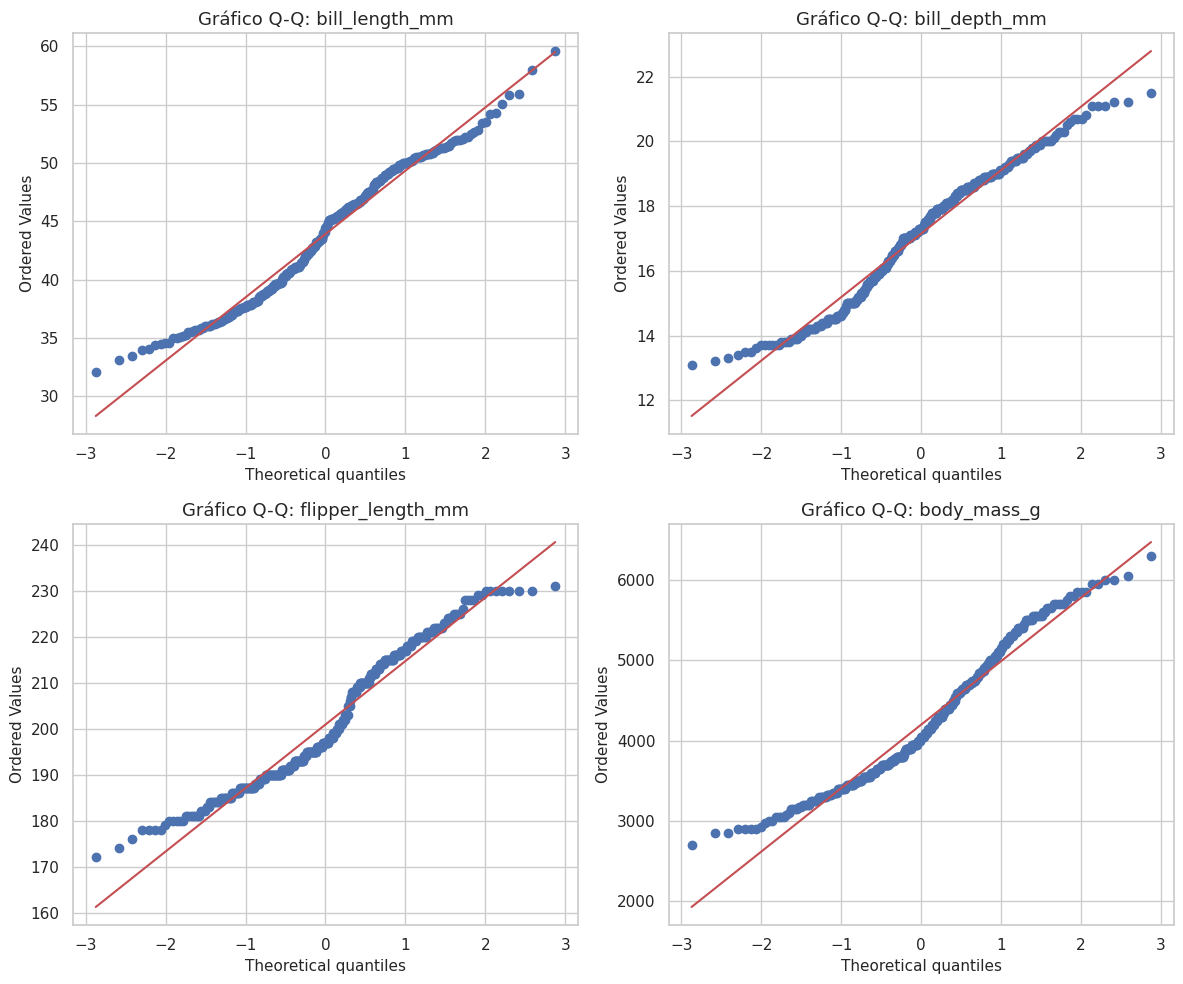

In [ ]:
resultados_normalidade = []
for especie, grupo in df.groupby('species', observed=True):
    for coluna in colunas_numericas:
        x = grupo[coluna].dropna()
        estatistica, p_valor = stats.shapiro(x)
        resultados_normalidade.append({
            'espécie': especie, 'variável': coluna, 'n': len(x),
            'W': estatistica, 'p_bruto': p_valor
        })

normalidade = pd.DataFrame(resultados_normalidade)
normalidade['p_holm'] = ajuste_holm(normalidade['p_bruto'])
normalidade['rejeita_normalidade_5%'] = normalidade['p_holm'] < 0.05
display(normalidade)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for coluna, ax in zip(colunas_numericas, axes.flat):
    stats.probplot(df[coluna].dropna(), dist='norm', plot=ax)
    ax.set_title(f'Gráfico Q-Q: {coluna}')
plt.tight_layout()
plt.show()

### Identificação de outliers univariados

A regra de 1,5 vezes o intervalo interquartil é aplicada dentro de cada espécie. Os registros sinalizados são candidatos à inspeção, não erros automáticos. Nenhuma observação é excluída nesta etapa.

In [ ]:
linhas_outliers = []
indices_sinalizados = set()

for especie, grupo in df.groupby('species', observed=True):
    for coluna in colunas_numericas:
        x = grupo[coluna].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr
        mascara = (grupo[coluna] < limite_inferior) | (grupo[coluna] > limite_superior)
        idx = grupo.index[mascara].tolist()
        indices_sinalizados.update(idx)
        linhas_outliers.append({
            'espécie': especie, 'variável': coluna,
            'limite_inferior': limite_inferior,
            'limite_superior': limite_superior,
            'n_sinalizados': len(idx),
        })

display(pd.DataFrame(linhas_outliers))
print(f'Linhas únicas sinalizadas por ao menos uma variável: {len(indices_sinalizados)}')
display(df.loc[sorted(indices_sinalizados)] if indices_sinalizados else pd.DataFrame())

,espécie,variável,limite_inferior,limite_superior,n_sinalizados
0,Adelie,bill_length_mm,30.7500,46.7500,0
1,Adelie,bill_depth_mm,15.2500,21.2500,1
2,Adelie,flipper_length_mm,172.5000,208.5000,2
3,Adelie,body_mass_g,"2,375.0000","4,975.0000",0
4,Chinstrap,bill_length_mm,39.2625,58.1625,0
5,Chinstrap,bill_depth_mm,14.6500,22.2500,0
6,Chinstrap,flipper_length_mm,176.0000,216.0000,0
7,Chinstrap,body_mass_g,"2,793.7500","4,643.7500",2
8,Gentoo,bill_length_mm,38.9250,55.9250,1
9,Gentoo,bill_depth_mm,11.9500,17.9500,0


Linhas únicas sinalizadas por ao menos uma variável: 6


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
19,Adelie,Torgersen,46.0000,21.5000,194.0000,"4,200.0000",Male,2007
28,Adelie,Biscoe,37.9000,18.6000,172.0000,"3,150.0000",Female,2007
129,Adelie,Torgersen,44.1000,18.0000,210.0000,"4,000.0000",Male,2009
185,Gentoo,Biscoe,59.6000,17.0000,230.0000,"6,050.0000",Male,2007
313,Chinstrap,Dream,52.0000,20.7000,210.0000,"4,800.0000",Male,2008
314,Chinstrap,Dream,46.9000,16.6000,192.0000,"2,700.0000",Female,2008


### Outliers multivariados pela distância de Mahalanobis

A distância de Mahalanobis considera simultaneamente as quatro medidas e suas covariâncias. O limite de 97,5% da distribuição qui-quadrado sinaliza combinações multivariadas incomuns. A mediana é utilizada somente para completar a matriz necessária ao cálculo.

In [ ]:
imputador_outlier = SimpleImputer(strategy='median')
X_outlier = imputador_outlier.fit_transform(df[colunas_numericas])
centro = X_outlier.mean(axis=0)
covariancia = np.cov(X_outlier, rowvar=False)
covariancia_inversa = np.linalg.pinv(covariancia)
diferencas = X_outlier - centro
distancias_quadradas = np.einsum(
    'ij,jk,ik->i', diferencas, covariancia_inversa, diferencas
)
limite_mahalanobis = stats.chi2.ppf(0.975, df=len(colunas_numericas))
mascara_multivariada = distancias_quadradas > limite_mahalanobis

outliers_multivariados = df.loc[mascara_multivariada].copy()
outliers_multivariados['distancia_mahalanobis_quadrada'] = distancias_quadradas[mascara_multivariada]
outliers_multivariados = outliers_multivariados.sort_values(
    'distancia_mahalanobis_quadrada', ascending=False
)
print(f'Limite qui-quadrado: {limite_mahalanobis:.4f}')
print(f'Observações sinalizadas: {mascara_multivariada.sum()}')
display(outliers_multivariados)

Limite qui-quadrado: 11.1433
Observações sinalizadas: 3


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,distancia_mahalanobis_quadrada
293,Chinstrap,Dream,58.0000,17.8000,181.0000,"3,700.0000",Female,2007,28.1094
14,Adelie,Torgersen,34.6000,21.1000,198.0000,"4,400.0000",Male,2007,13.4966
39,Adelie,Dream,39.8000,19.1000,184.0000,"4,650.0000",Male,2007,12.2579


## 5. Análises bivariadas e comparações entre grupos

As estatísticas agrupadas permitem comparar localização e dispersão sem reduzir a análise a um único teste de hipótese.

In [ ]:
resumo_por_especie = (
    df.groupby('species', observed=True)[colunas_numericas]
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
)
display(resumo_por_especie)

resumo_especie_sexo = (
    df.groupby(['species', 'sex'], observed=True)[colunas_numericas]
    .agg(['count', 'mean', 'std'])
)
display(resumo_especie_sexo)

bill_length_mm                                        bill_depth_mm  \
                   count    mean  median    std     min     max         count   
species                                                                         
Adelie               151 38.7914 38.8000 2.6634 32.1000 46.0000           151   
Chinstrap             68 48.8338 49.5500 3.3393 40.9000 58.0000            68   
Gentoo               123 47.5049 47.3000 3.0819 40.9000 59.6000           123   

                                                 flipper_length_mm           \
             mean  median    std     min     max             count     mean   
species                                                                       
Adelie    18.3464 18.4000 1.2166 15.5000 21.5000               151 189.9536   
Chinstrap 18.4206 18.4500 1.1354 16.4000 20.8000                68 195.8235   
Gentoo    14.9821 15.0000 0.9812 13.1000 17.3000               123 217.1870   

                                            body_mass_g                        \
            median    std      min      max       count       mean     median   
species                                                                         
Adelie    190.0000 6.5395 172.0000 210.0000         151 3,700.6623 3,700.0000   
Chinstrap 196.0000 7.1319 178.0000 212.0000          68 3,733.0882 3,700.0000   
Gentoo    216.0000 6.4850 203.0000 231.0000         123 5,076.0163 5,000.0000   

                                          
               std        min        max  
species                                   
Adelie    458.5661 2,850.0000 4,775.0000  
Chinstrap 384.3351 2,700.0000 4,800.0000  
Gentoo    504.1162 3,950.0000 6,300.0000

bill_length_mm                bill_depth_mm                 \
                          count    mean    std         count    mean    std   
species   sex                                                                 
Adelie    Female             73 37.2575 2.0289            73 17.6219 0.9430   
          Male               73 40.3904 2.2771            73 19.0726 1.0189   
Chinstrap Female             34 46.5735 3.1087            34 17.5882 0.7811   
          Male               34 51.0941 1.5646            34 19.2529 0.7613   
Gentoo    Female             58 45.5638 2.0512            58 14.2379 0.5402   
          Male               61 49.4738 2.7206            61 15.7180 0.7411   

                 flipper_length_mm                 body_mass_g             \
                             count     mean    std       count       mean   
species   sex                                                               
Adelie    Female                73 187.7945 5.5950          73 3,368.8356   
          Male                  73 192.4110 6.5993          73 4,043.4932   
Chinstrap Female                34 191.7353 5.7541          34 3,527.2059   
          Male                  34 199.9118 5.9766          34 3,938.9706   
Gentoo    Female                58 212.7069 3.8979          58 4,679.7414   
          Male                  61 221.5410 5.6733          61 5,484.8361   

                           
                      std  
species   sex              
Adelie    Female 269.3801  
          Male   346.8116  
Chinstrap Female 285.3339  
          Male   362.1376  
Gentoo    Female 281.5783  
          Male   313.1586

### Relações gráficas entre variáveis quantitativas

O diagrama de pares permite avaliar forma, direção, intensidade, agrupamentos e observações incomuns. A cor identifica a espécie, o que ajuda a reconhecer correlações produzidas ou modificadas pela composição dos grupos.

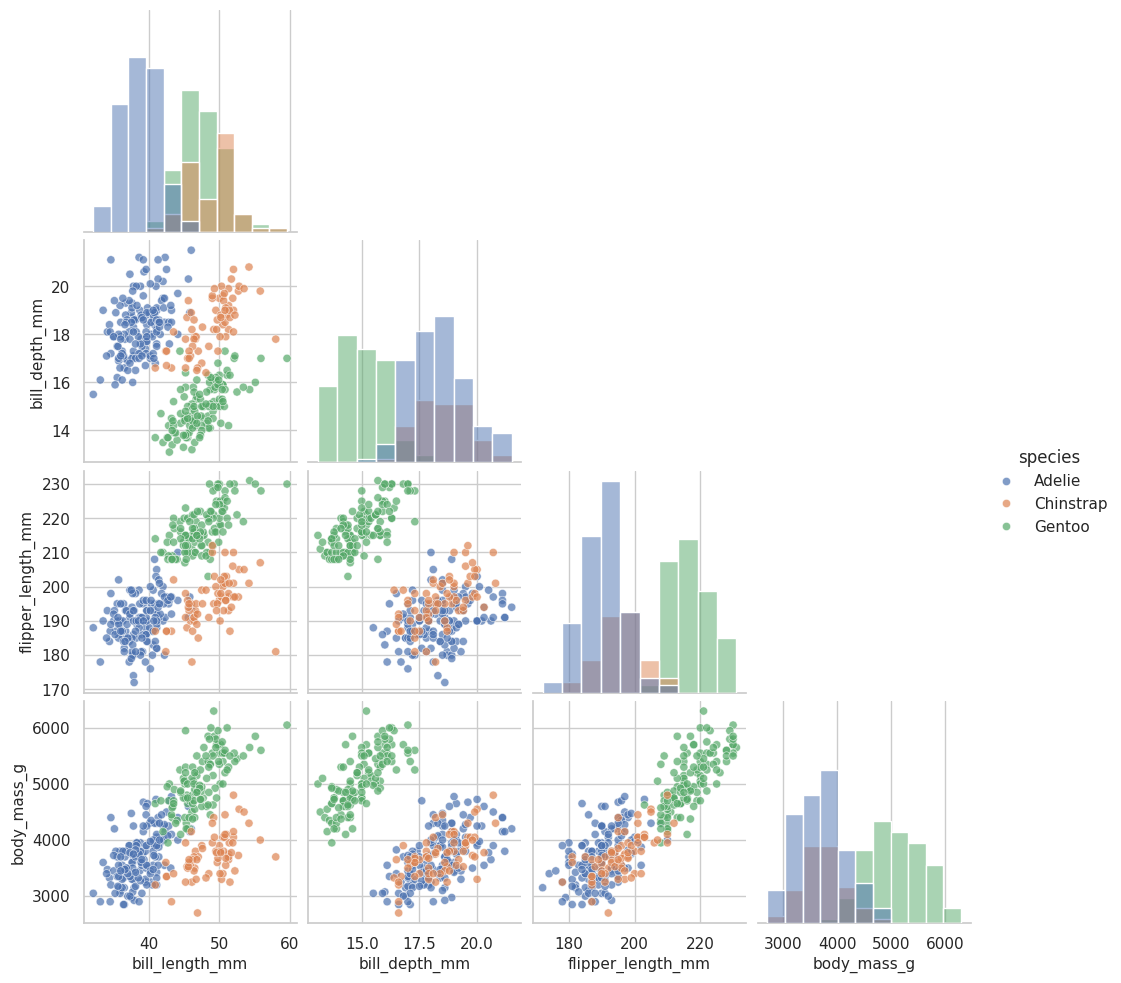

In [ ]:
sns.pairplot(
    df, vars=colunas_numericas, hue='species',
    corner=True, diag_kind='hist', plot_kws={'alpha': 0.70, 's': 35}
)
plt.show()

### Covariância e correlações

A covariância preserva as unidades originais. A correlação de Pearson mede associação linear. A correlação de Spearman mede associação monotônica por postos e tende a ser menos sensível a assimetria e valores extremos. Os cálculos utilizam pares disponíveis em cada combinação de variáveis.

Matriz de covariância


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,29.8071,-2.5342,50.3758,"2,605.5919"
bill_depth_mm,-2.5342,3.8998,-16.2130,-747.3701
flipper_length_mm,50.3758,-16.2130,197.7318,"9,824.4161"
body_mass_g,"2,605.5919",-747.3701,"9,824.4161","643,131.0773"


Correlação de Pearson


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.0000,-0.2351,0.6562,0.5951
bill_depth_mm,-0.2351,1.0000,-0.5839,-0.4719
flipper_length_mm,0.6562,-0.5839,1.0000,0.8712
body_mass_g,0.5951,-0.4719,0.8712,1.0000


Correlação de Spearman


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.0000,-0.2217,0.6728,0.5838
bill_depth_mm,-0.2217,1.0000,-0.5233,-0.4324
flipper_length_mm,0.6728,-0.5233,1.0000,0.8400
body_mass_g,0.5838,-0.4324,0.8400,1.0000


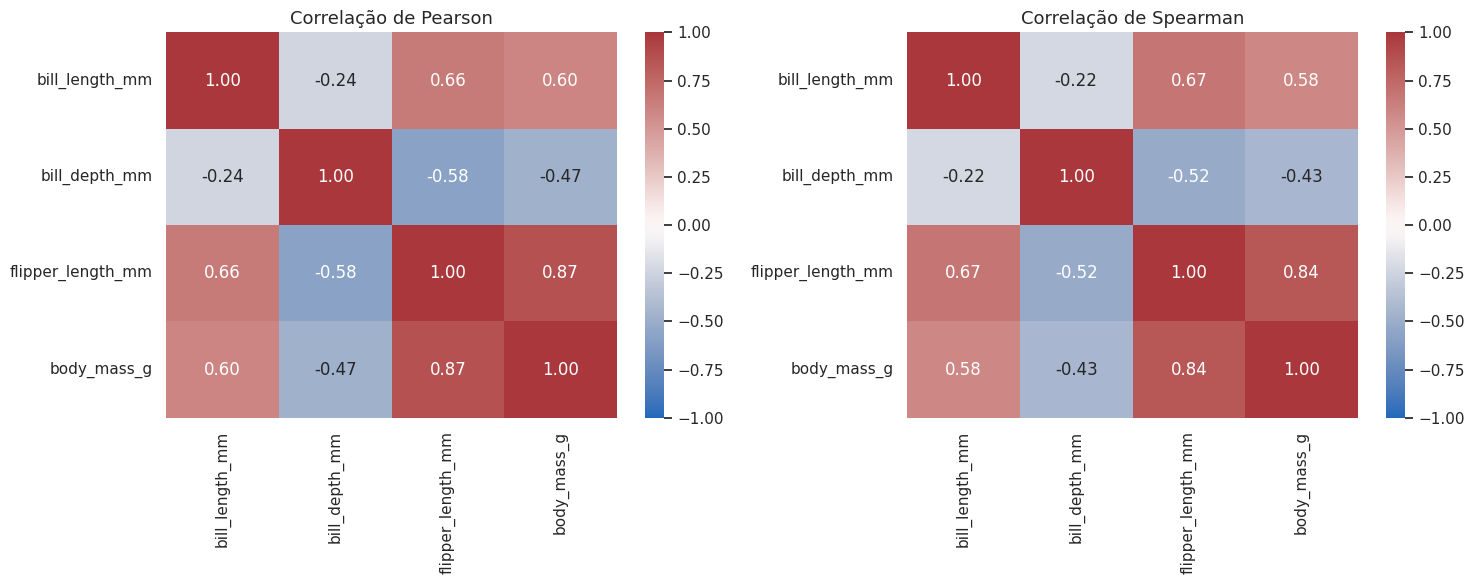

In [ ]:
matriz_covariancia = df[colunas_numericas].cov()
correlacao_pearson = df[colunas_numericas].corr(method='pearson')
correlacao_spearman = df[colunas_numericas].corr(method='spearman')

print('Matriz de covariância')
display(matriz_covariancia)
print('Correlação de Pearson')
display(correlacao_pearson)
print('Correlação de Spearman')
display(correlacao_spearman)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(correlacao_pearson, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Correlação de Pearson')
sns.heatmap(correlacao_spearman, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Correlação de Spearman')
plt.tight_layout()
plt.show()

### Significância das correlações

Cada par é testado com Pearson e Spearman. O método de Holm controla o erro familiar provocado por múltiplas comparações. A magnitude do coeficiente deve ser interpretada junto ao intervalo, ao gráfico e ao contexto, não apenas pelo valor p.

In [ ]:
resultados_correlacao = []
for var_1, var_2 in itertools.combinations(colunas_numericas, 2):
    pares = df[[var_1, var_2]].dropna()
    r_pearson, p_pearson = stats.pearsonr(pares[var_1], pares[var_2])
    rho_spearman, p_spearman = stats.spearmanr(pares[var_1], pares[var_2])
    resultados_correlacao.append({
        'variável_1': var_1, 'variável_2': var_2, 'n': len(pares),
        'r_pearson': r_pearson, 'p_pearson': p_pearson,
        'rho_spearman': rho_spearman, 'p_spearman': p_spearman,
    })

tabela_correlacoes = pd.DataFrame(resultados_correlacao)
tabela_correlacoes['p_pearson_holm'] = ajuste_holm(
    tabela_correlacoes['p_pearson']
)
tabela_correlacoes['p_spearman_holm'] = ajuste_holm(
    tabela_correlacoes['p_spearman']
)
display(tabela_correlacoes.sort_values('r_pearson', key=np.abs, ascending=False))

,variável_1,variável_2,n,r_pearson,p_pearson,rho_spearman,p_spearman,p_pearson_holm,p_spearman_holm
5,flipper_length_mm,body_mass_g,342,0.8712,0.0000,0.8400,0.0000,0.0000,0.0000
1,bill_length_mm,flipper_length_mm,342,0.6562,0.0000,0.6728,0.0000,0.0000,0.0000
2,bill_length_mm,body_mass_g,342,0.5951,0.0000,0.5838,0.0000,0.0000,0.0000
3,bill_depth_mm,flipper_length_mm,342,-0.5839,0.0000,-0.5233,0.0000,0.0000,0.0000
4,bill_depth_mm,body_mass_g,342,-0.4719,0.0000,-0.4324,0.0000,0.0000,0.0000
0,bill_length_mm,bill_depth_mm,342,-0.2351,0.0000,-0.2217,0.0000,0.0000,0.0000


### Associações entre variáveis categóricas

O teste qui-quadrado avalia independência. O V de Cramér corrigido quantifica a intensidade da associação em escala de zero a um. Frequências esperadas pequenas indicam que a aproximação do qui-quadrado deve ser interpretada com cautela.

In [ ]:
def cramers_v_corrigido(tabela):
    qui2, p_valor, gl, esperadas = stats.chi2_contingency(tabela)
    n = tabela.to_numpy().sum()
    linhas, colunas = tabela.shape
    phi2 = qui2 / n
    phi2_corr = max(0, phi2 - ((colunas - 1) * (linhas - 1)) / (n - 1))
    linhas_corr = linhas - ((linhas - 1) ** 2) / (n - 1)
    colunas_corr = colunas - ((colunas - 1) ** 2) / (n - 1)
    denominador = min(colunas_corr - 1, linhas_corr - 1)
    v = np.sqrt(phi2_corr / denominador) if denominador > 0 else np.nan
    return qui2, p_valor, gl, esperadas, v

categoricas_associacao = ['species', 'island', 'sex', 'year']
resultados_categoricos = []

for var_1, var_2 in itertools.combinations(categoricas_associacao, 2):
    tabela = pd.crosstab(df[var_1], df[var_2])
    qui2, p_valor, gl, esperadas, v = cramers_v_corrigido(tabela)
    resultados_categoricos.append({
        'variável_1': var_1, 'variável_2': var_2,
        'qui2': qui2, 'gl': gl, 'p_bruto': p_valor,
        'v_cramer_corrigido': v,
        'menor_frequência_esperada': esperadas.min(),
        'esperadas_menores_5_%': 100 * (esperadas < 5).mean(),
    })

associacoes_categoricas = pd.DataFrame(resultados_categoricos)
associacoes_categoricas['p_holm'] = ajuste_holm(
    associacoes_categoricas['p_bruto']
)
display(associacoes_categoricas.sort_values('v_cramer_corrigido', ascending=False))

tabela_especie_ilha = pd.crosstab(df['species'], df['island'])
qui2, _, _, esperadas, _ = cramers_v_corrigido(tabela_especie_ilha)
residuos_padronizados = (tabela_especie_ilha - esperadas) / np.sqrt(esperadas)
print('Tabela de contingência entre espécie e ilha')
display(tabela_especie_ilha)
print('Resíduos padronizados')
display(residuos_padronizados)

,variável_1,variável_2,qui2,gl,p_bruto,v_cramer_corrigido,menor_frequência_esperada,esperadas_menores_5_%,p_holm
0,species,island,299.5503,4,0.0000,0.6573,10.2791,0.0000,0.0000
4,island,year,6.3153,4,0.1768,0.0580,16.6279,0.0000,0.8840
1,species,sex,0.0486,2,0.9760,0.0000,33.6937,0.0000,1.0000
2,species,year,3.2156,4,0.5224,0.0000,21.7442,0.0000,1.0000
3,island,sex,0.0576,2,0.9716,0.0000,23.2883,0.0000,1.0000
5,sex,year,0.0001,2,1.0000,0.0000,51.0360,0.0000,1.0000


Tabela de contingência entre espécie e ilha


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


Resíduos padronizados


island,Biscoe,Dream,Torgersen
species,,,
Adelie,-3.5090,0.1634,6.0548
Chinstrap,-5.7628,8.7839,-3.2061
Gentoo,8.1525,-6.6856,-4.3295


### Comparação entre dois grupos

Fêmeas e machos são comparados dentro de cada espécie para reduzir o confundimento provocado pelas diferenças entre espécies. O teste t de Welch compara médias sem pressupor variâncias iguais. Mann-Whitney compara distribuições por postos. O g de Hedges fornece tamanho de efeito padronizado com correção para amostras finitas.

In [ ]:
def hedges_g(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    nx, ny = len(x), len(y)
    variancia_agrupada = (
        ((nx - 1) * x.var(ddof=1) + (ny - 1) * y.var(ddof=1))
        / (nx + ny - 2)
    )
    d = (x.mean() - y.mean()) / np.sqrt(variancia_agrupada)
    correcao = 1 - 3 / (4 * (nx + ny) - 9)
    return correcao * d

comparacoes_sexo = []
for especie, grupo in df.dropna(subset=['sex']).groupby('species', observed=True):
    for coluna in colunas_numericas:
        feminino = grupo.loc[grupo['sex'] == 'Female', coluna].dropna().to_numpy()
        masculino = grupo.loc[grupo['sex'] == 'Male', coluna].dropna().to_numpy()
        t_est, p_t = stats.ttest_ind(feminino, masculino, equal_var=False)
        u_est, p_u = stats.mannwhitneyu(feminino, masculino, alternative='two-sided')
        comparacoes_sexo.append({
            'espécie': especie, 'variável': coluna,
            'n_fêmeas': len(feminino), 'n_machos': len(masculino),
            'média_fêmeas': feminino.mean(), 'média_machos': masculino.mean(),
            't_welch': t_est, 'p_t': p_t,
            'U_mann_whitney': u_est, 'p_u': p_u,
            'g_hedges_fêmeas_menos_machos': hedges_g(feminino, masculino),
        })

comparacoes_sexo = pd.DataFrame(comparacoes_sexo)
comparacoes_sexo['p_t_holm'] = ajuste_holm(comparacoes_sexo['p_t'])
comparacoes_sexo['p_u_holm'] = ajuste_holm(comparacoes_sexo['p_u'])
display(comparacoes_sexo)

,espécie,variável,n_fêmeas,n_machos,média_fêmeas,média_machos,t_welch,p_t,U_mann_whitney,p_u,g_hedges_fêmeas_menos_machos,p_t_holm,p_u_holm
0,Adelie,bill_length_mm,73,73,37.2575,40.3904,-8.7765,0.0000,793.0000,0.0000,-1.4451,0.0000,0.0000
1,Adelie,bill_depth_mm,73,73,17.6219,19.0726,-8.9280,0.0000,746.5000,0.0000,-1.4701,0.0000,0.0000
2,Adelie,flipper_length_mm,73,73,187.7945,192.4110,-4.5589,0.0000,"1,567.0000",0.0000,-0.7507,0.0000,0.0000
3,Adelie,body_mass_g,73,73,"3,368.8356","4,043.4932",-13.1263,0.0000,310.5000,0.0000,-2.1613,0.0000,0.0000
4,Chinstrap,bill_length_mm,34,34,46.5735,51.0941,-7.5741,0.0000,88.5000,0.0000,-1.8160,0.0000,0.0000
5,Chinstrap,bill_depth_mm,34,34,17.5882,19.2529,-8.8994,0.0000,73.5000,0.0000,-2.1338,0.0000,0.0000
6,Chinstrap,flipper_length_mm,34,34,191.7353,199.9118,-5.7467,0.0000,190.5000,0.0000,-1.3779,0.0000,0.0000
7,Chinstrap,body_mass_g,34,34,"3,527.2059","3,938.9706",-5.2077,0.0000,206.5000,0.0000,-1.2487,0.0000,0.0000
8,Gentoo,bill_length_mm,58,61,45.5638,49.4738,-8.8798,0.0000,412.5000,0.0000,-1.6068,0.0000,0.0000
9,Gentoo,bill_depth_mm,58,61,14.2379,15.7180,-12.4935,0.0000,184.0000,0.0000,-2.2589,0.0000,0.0000


### Comparação entre três espécies

O teste de Levene avalia homogeneidade de variâncias. A ANOVA de Welch compara médias com variâncias possivelmente diferentes. Kruskal-Wallis fornece uma alternativa por postos. Eta quadrado e epsilon quadrado estimam o tamanho do efeito global. Comparações posteriores são feitas aos pares com teste t de Welch e correção de Holm.

In [ ]:
def eta_quadrado(dados, grupo, resposta):
    base = dados[[grupo, resposta]].dropna()
    media_geral = base[resposta].mean()
    soma_total = ((base[resposta] - media_geral) ** 2).sum()
    soma_entre = sum(
        len(g) * (g[resposta].mean() - media_geral) ** 2
        for _, g in base.groupby(grupo, observed=True)
    )
    return soma_entre / soma_total

resultados_especies = []
for coluna in colunas_numericas:
    grupos = [
        grupo[coluna].dropna().to_numpy()
        for _, grupo in df.groupby('species', observed=True)
    ]
    levene_est, p_levene = stats.levene(*grupos, center='median')
    f_welch, p_welch, gl_1, gl_2 = anova_welch(grupos)
    h_est, p_kruskal = stats.kruskal(*grupos)
    n_total = sum(len(g) for g in grupos)
    k = len(grupos)
    epsilon2 = max(0, (h_est - k + 1) / (n_total - k))
    resultados_especies.append({
        'variável': coluna,
        'levene': levene_est, 'p_levene': p_levene,
        'F_welch': f_welch, 'gl1_welch': gl_1, 'gl2_welch': gl_2,
        'p_welch': p_welch,
        'H_kruskal': h_est, 'p_kruskal': p_kruskal,
        'eta_quadrado': eta_quadrado(df, 'species', coluna),
        'epsilon_quadrado': epsilon2,
    })

comparacao_especies = pd.DataFrame(resultados_especies)
comparacao_especies['p_welch_holm'] = ajuste_holm(
    comparacao_especies['p_welch']
)
comparacao_especies['p_kruskal_holm'] = ajuste_holm(
    comparacao_especies['p_kruskal']
)
display(comparacao_especies)

post_hoc = []
especies = df['species'].dropna().unique().tolist()
for coluna in colunas_numericas:
    for especie_1, especie_2 in itertools.combinations(especies, 2):
        x = df.loc[df['species'] == especie_1, coluna].dropna()
        y = df.loc[df['species'] == especie_2, coluna].dropna()
        t_est, p_valor = stats.ttest_ind(x, y, equal_var=False)
        post_hoc.append({
            'variável': coluna, 'espécie_1': especie_1, 'espécie_2': especie_2,
            'diferença_médias': x.mean() - y.mean(),
            't_welch': t_est, 'p_bruto': p_valor,
            'g_hedges': hedges_g(x, y),
        })

post_hoc = pd.DataFrame(post_hoc)
post_hoc['p_holm'] = ajuste_holm(post_hoc['p_bruto'])
display(post_hoc.sort_values(['variável', 'p_holm']))

,variável,levene,p_levene,F_welch,gl1_welch,gl2_welch,p_welch,H_kruskal,p_kruskal,eta_quadrado,epsilon_quadrado,p_welch_holm,p_kruskal_holm
0,bill_length_mm,2.2425,0.1078,421.7749,2,166.4742,0.0000,244.1367,0.0000,0.7078,0.7143,0.0000,0.0000
1,bill_depth_mm,2.0369,0.1320,400.6055,2,177.1486,0.0000,224.5631,0.0000,0.6798,0.6565,0.0000,0.0000
2,flipper_length_mm,0.3306,0.7188,614.0103,2,172.7576,0.0000,244.8905,0.0000,0.7782,0.7165,0.0000,0.0000
3,body_mass_g,5.1203,0.0064,317.5723,2,189.4784,0.0000,217.5992,0.0000,0.6697,0.6360,0.0000,0.0000


,variável,espécie_1,espécie_2,diferença_médias,t_welch,p_bruto,g_hedges,p_holm
3,bill_depth_mm,Adelie,Gentoo,3.3642,25.3370,0.0000,3.0030,0.0000
5,bill_depth_mm,Gentoo,Chinstrap,-3.4385,-21.0096,0.0000,-3.2979,0.0000
4,bill_depth_mm,Adelie,Chinstrap,-0.0742,-0.4377,0.6623,-0.0621,1.0000
0,bill_length_mm,Adelie,Gentoo,-8.7135,-24.7251,0.0000,-3.0397,0.0000
1,bill_length_mm,Adelie,Chinstrap,-10.0424,-21.8646,0.0000,-3.4641,0.0000
2,bill_length_mm,Gentoo,Chinstrap,-1.3289,-2.7060,0.0077,-0.4168,0.0232
9,body_mass_g,Adelie,Gentoo,"-1,375.3540",-23.3860,0.0000,-2.8602,0.0000
11,body_mass_g,Gentoo,Chinstrap,"1,342.9280",20.6278,0.0000,2.8753,0.0000
10,body_mass_g,Adelie,Chinstrap,-32.4260,-0.5431,0.5879,-0.0739,1.0000
6,flipper_length_mm,Adelie,Gentoo,-27.2333,-34.4445,0.0000,-4.1685,0.0000


## 6. Análise de Componentes Principais

A PCA reduz a dimensionalidade ao criar combinações lineares ortogonais das variáveis quantitativas. Como as medidas possuem unidades e escalas diferentes, a padronização é obrigatória. As categorias não entram no cálculo e são usadas apenas para interpretar os escores. Ausências quantitativas são preenchidas pela mediana para preservar todas as linhas, com a decisão registrada explicitamente.

### Adequação da matriz para PCA

O teste de esfericidade de Bartlett verifica se a matriz de correlação difere de uma matriz identidade. O índice KMO compara correlações simples e parciais. Valores mais próximos de um indicam maior proporção de variância compartilhada. Esses diagnósticos são auxiliares e não substituem a interpretação substantiva das variáveis.

In [ ]:
def teste_bartlett_esfericidade(X):
    X = np.asarray(X, dtype=float)
    n, p = X.shape
    R = np.corrcoef(X, rowvar=False)
    determinante = np.linalg.det(R)
    qui2 = -(n - 1 - (2 * p + 5) / 6) * np.log(determinante)
    gl = p * (p - 1) / 2
    p_valor = stats.chi2.sf(qui2, gl)
    return qui2, gl, p_valor

def indice_kmo(X, nomes):
    X = np.asarray(X, dtype=float)
    R = np.corrcoef(X, rowvar=False)
    R_inv = np.linalg.pinv(R)
    parcial = -R_inv / np.sqrt(np.outer(np.diag(R_inv), np.diag(R_inv)))
    np.fill_diagonal(R, 0)
    np.fill_diagonal(parcial, 0)
    r2 = R ** 2
    p2 = parcial ** 2
    kmo_variaveis = r2.sum(axis=0) / (r2.sum(axis=0) + p2.sum(axis=0))
    kmo_geral = r2.sum() / (r2.sum() + p2.sum())
    return kmo_geral, pd.Series(kmo_variaveis, index=nomes, name='KMO')

X_completo = df[colunas_numericas].dropna().to_numpy()
qui2_bartlett, gl_bartlett, p_bartlett = teste_bartlett_esfericidade(X_completo)
kmo_geral, kmo_variaveis = indice_kmo(X_completo, colunas_numericas)

print(f'Bartlett: qui2={qui2_bartlett:.4f}, gl={gl_bartlett:.0f}, p={p_bartlett:.6g}')
print(f'KMO geral: {kmo_geral:.4f}')
display(kmo_variaveis.to_frame())

Bartlett: qui2=838.0788, gl=6, p=9.10043e-178
KMO geral: 0.6871


,KMO
bill_length_mm,0.7880
bill_depth_mm,0.6995
flipper_length_mm,0.6245
body_mass_g,0.7056


### Imputação, padronização e ajuste da PCA

O número de componentes é igual ao número de variáveis originais. São apresentados o autovalor, a variância explicada individual e a variância acumulada. O critério de Kaiser mantém componentes com autovalor maior que um; o limiar acumulado informa quantos componentes são necessários para explicar pelo menos 90% da variância.

In [ ]:
imputador_pca = SimpleImputer(strategy='median')
padronizador = StandardScaler()

X_imputado = imputador_pca.fit_transform(df[colunas_numericas])
X_padronizado = padronizador.fit_transform(X_imputado)

pca = PCA()
escores = pca.fit_transform(X_padronizado)
nomes_componentes = [f'PC{i}' for i in range(1, len(colunas_numericas) + 1)]

resumo_pca = pd.DataFrame({
    'componente': nomes_componentes,
    'autovalor': pca.explained_variance_,
    'variância_explicada_%': 100 * pca.explained_variance_ratio_,
    'variância_acumulada_%': 100 * np.cumsum(pca.explained_variance_ratio_),
})
display(resumo_pca)

n_kaiser = int((pca.explained_variance_ > 1).sum())
n_90 = int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.90) + 1)
print(f'Componentes pelo critério de Kaiser: {n_kaiser}')
print(f'Componentes para atingir ao menos 90% da variância: {n_90}')

,componente,autovalor,variância_explicada_%,variância_acumulada_%
0,PC1,2.7615,68.8372,68.8372
1,PC2,0.7748,19.3136,88.1508
2,PC3,0.3665,9.1361,97.2869
3,PC4,0.1088,2.7131,100.0000


Componentes pelo critério de Kaiser: 1
Componentes para atingir ao menos 90% da variância: 3


In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.bar(
    resumo_pca['componente'], resumo_pca['variância_explicada_%'],
    color='#377eb8', alpha=0.80, label='Variância individual'
)
ax1.set_xlabel('Componente principal')
ax1.set_ylabel('Variância explicada individual (%)', color='#377eb8')
ax1.tick_params(axis='y', labelcolor='#377eb8')

ax2 = ax1.twinx()
ax2.plot(
    resumo_pca['componente'], resumo_pca['variância_acumulada_%'],
    color='#e41a1c', marker='o', linewidth=2, label='Variância acumulada'
)
ax2.axhline(90, color='gray', linestyle=':', label='Limiar de 90%')
ax2.set_ylabel('Variância acumulada (%)', color='#e41a1c')
ax2.set_ylim(0, 105)
ax2.tick_params(axis='y', labelcolor='#e41a1c')
ax1.set_title('Scree plot e variância acumulada')
fig.tight_layout()
plt.show()

### Cargas e contribuições das variáveis

As cargas representam a correlação aproximada entre cada variável padronizada e cada componente. O sinal indica direção e o módulo indica intensidade. A contribuição percentual mostra quanto cada variável participa da definição de um componente.

In [ ]:
cargas = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    index=colunas_numericas,
    columns=nomes_componentes,
)
contribuicoes = 100 * cargas.pow(2).div(cargas.pow(2).sum(axis=0), axis=1)

print('Cargas dos componentes')
display(cargas)
print('Contribuição percentual das variáveis')
display(contribuicoes)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cargas, annot=True, fmt='.2f', cmap='vlag', center=0, ax=axes[0])
axes[0].set_title('Cargas da PCA')
sns.heatmap(contribuicoes, annot=True, fmt='.1f', cmap='Blues', ax=axes[1])
axes[1].set_title('Contribuições (%)')
plt.tight_layout()
plt.show()

### Escores e biplot

Os escores posicionam cada observação no espaço dos componentes. A separação por cor permite verificar se a estrutura multivariada coincide com as espécies. No biplot, vetores próximos indicam variáveis positivamente relacionadas, vetores opostos indicam relação negativa e vetores aproximadamente perpendiculares indicam relação fraca.

In [ ]:
escores_df = pd.DataFrame(escores, columns=nomes_componentes, index=df.index)
escores_df = pd.concat(
    [escores_df, df[['species', 'island', 'sex', 'year']]], axis=1
)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=escores_df, x='PC1', y='PC2',
    hue='species', style='sex', s=70, alpha=0.80
)
plt.axhline(0, color='gray', linewidth=0.8)
plt.axvline(0, color='gray', linewidth=0.8)
plt.xlabel(f"PC1 ({100 * pca.explained_variance_ratio_[0]:.1f}% da variância)")
plt.ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.1f}% da variância)")
plt.title('Escores das duas primeiras componentes')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
sns.scatterplot(
    data=escores_df, x='PC1', y='PC2', hue='species',
    s=55, alpha=0.60, ax=ax
)
escala_x = np.max(np.abs(escores[:, 0])) * 0.85
escala_y = np.max(np.abs(escores[:, 1])) * 0.85
for variavel in colunas_numericas:
    x = cargas.loc[variavel, 'PC1'] * escala_x
    y = cargas.loc[variavel, 'PC2'] * escala_y
    ax.arrow(0, 0, x, y, color='black', alpha=0.75, width=0.01, head_width=0.12)
    ax.text(x * 1.08, y * 1.08, variavel, ha='center', va='center', fontsize=10)
ax.axhline(0, color='gray', linewidth=0.8)
ax.axvline(0, color='gray', linewidth=0.8)
ax.set_xlabel(f"PC1 ({100 * pca.explained_variance_ratio_[0]:.1f}%)")
ax.set_ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.1f}%)")
ax.set_title('Biplot das duas primeiras componentes')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 7. Exportação dos resultados preparados

A base limpa mantém ausências legítimas e não remove observações apenas por terem sido sinalizadas como outliers. Os escores da PCA são exportados separadamente. Os arquivos são gravados no diretório temporário da sessão do Colab.

In [ ]:
ARQUIVO_LIMPO = 'palmer_penguins_limpo.csv'
ARQUIVO_PCA = 'palmer_penguins_escores_pca.csv'

df.to_csv(ARQUIVO_LIMPO, index=False)
escores_df.to_csv(ARQUIVO_PCA, index=False)

print(f'Arquivo criado: {ARQUIVO_LIMPO}')
print(f'Arquivo criado: {ARQUIVO_PCA}')

# Para baixar os arquivos no Google Colab, remova os comentários abaixo.
# from google.colab import files
# files.download(ARQUIVO_LIMPO)
# files.download(ARQUIVO_PCA)

## Encerramento

O fluxo termina após a análise exploratória multivariada. A base foi carregada, auditada, limpa, descrita e examinada por métodos univariados, bivariados e multivariados. A etapa seguinte em um projeto analítico poderia utilizar essas evidências para definir variáveis, hipóteses e estratégias de validação, mas regressão, classificação e demais modelos preditivos não fazem parte deste notebook.